# **reconaissance voyelle**

In [ ]:
import numpy as np
import msicpe.mana as mana
import msicpe.san as san
import pandas as pd
import msicpe.san as san
from plotly import express as px
import matplotlib.pyplot as plt
import scipy as signal

In [ ]:
signal_dict = np.load('data partie 2/apprentissage/a_1.npz') # signal_dict est un dictionnaire
s = signal_dict['s'] # extraction du signal utile
t = signal_dict['t']        

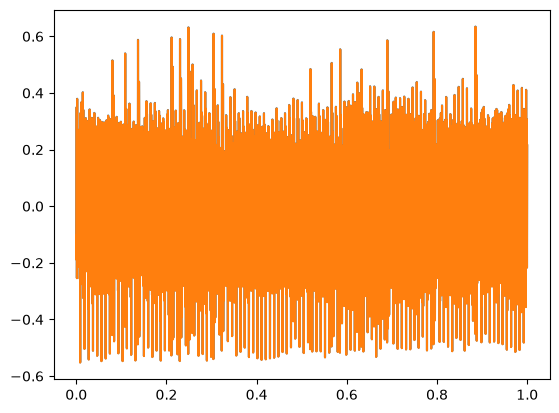

In [ ]:
s_centre = s - np.mean(s)
plt.plot(t,s)
plt.plot(t,s_centre)

In [ ]:
nu, S = san.trans_fourier(s_centre, t)

spectre = np.abs(S)

df = pd.DataFrame({"nu": nu, "spectre": spectre})

fig = px.line(
    df, 
    x="nu", 
    y=["spectre"], 
    title="Courbe de la fonction"
)
fig.show()

#plt.plot(nu, spectre)

/Users/adel/Documents/code/env_cpe/lib/python3.12/site-packages/matplotlib/cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/adel/Documents/code/env_cpe/lib/python3.12/site-packages/matplotlib/cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


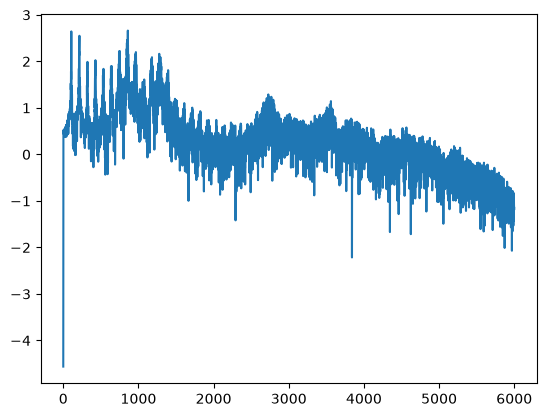

In [ ]:
plt.plot(nu, np.log10(S))

In [ ]:
def vect_signal(chemin, H):
    dat = np.load(chemin)
    s = dat['s']
    t = dat['t']

    s = s - np.mean(s) # centrage du signal

    # Calcul du spectre et normalisation
    nu, sig = san.trans_fourier(s, t)
    spectre = np.abs(sig)
    spectre_norm = spectre / np.max(spectre)

    # Détection de f0
    f0 = san.detect_fondamentale(spectre_norm, nu)

    # Création de la liste des H + 1 fréquences : [f0, 2*f0, ..., (H+1)*f0]
    freq_list = [k * f0 for k in range(1, H + 2)]

    # Extraction des amplitudes des pics
    _, peak_amplitudes = san.detect_pics(spectre_norm, freq_list, nu)

    # Renvoi du vecteur caractéristique en échelle logarithmique (taille H + 1)
    return np.log10(peak_amplitudes)

print(vect_signal('/Users/adel/Documents/code/SAN/Projet SAN/data partie 2/etude/BON_signal_3.npz',11))

[-0.12075384  0.         -1.4711585  -2.3327425  -2.80172    -2.4447694
 -2.6249788  -2.8398972  -2.854561   -2.8098037  -2.9446673  -3.0266018 ]


[-0.00310862 -0.20122435 -1.18659726 -1.86827559 -2.14342301 -2.42528648
 -2.79851856 -2.88631005 -2.8463057  -2.86146979 -2.53863468 -2.17569888
 -2.29296179 -2.33411686]


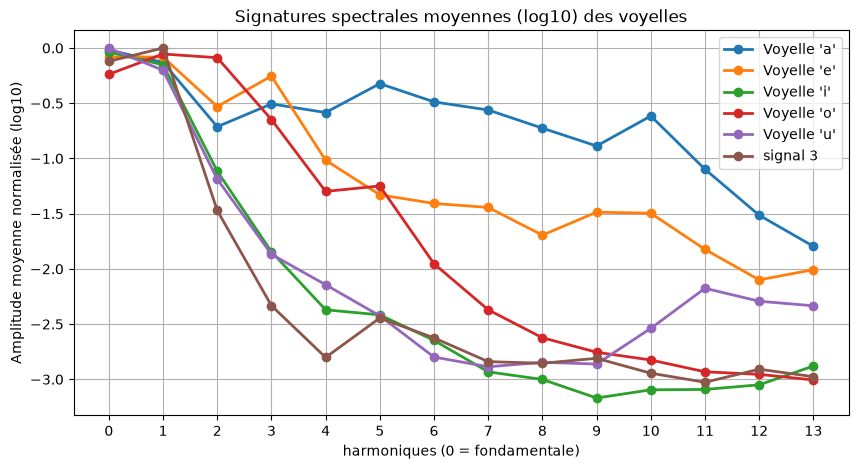

In [ ]:
voyelles = ['a', 'e', 'i', 'o', 'u'] 
H = 13  # Nombre d'harmoniques (vecteur final de dimension H + 1)
nb_sons = 5

dico_vects = {}
harmoniques = np.arange(0, H + 1) # Que pour le tracé

plt.figure(figsize=(10, 5))

for v in voyelles:
    vecteurs = np.zeros((nb_sons, H + 1))

    for i in range(1, nb_sons + 1):

        # Stockage en échelle logarithmique (base 10)
        vecteurs[i - 1, :] = vect_signal(f'data partie 2/apprentissage/{v}_{i}.npz',H)

    # Calcul et sauvegarde du vecteur moyen pour la voyelle v
    dico_vects[v] = np.mean(vecteurs, axis=0)

    # Tracé du vecteur moyen
    plt.plot(
        harmoniques,
        dico_vects[v],
        '-o',
        linewidth=2,
        label=f"Voyelle '{v}'",
    )


#plot du signal d'etude 3
plt.plot(
        harmoniques,
        vect_signal('data partie 2/etude/BON_signal_3.npz',H),
        '-o',
        linewidth=2,
        label="signal 3",
    )

plt.title('Signatures spectrales moyennes (log10) des voyelles')
plt.xlabel('harmoniques (0 = fondamentale)')
plt.ylabel('Amplitude moyenne normalisée (log10)')
plt.xticks(harmoniques)
plt.grid(True)
plt.legend()
plt.show()

In [ ]:

voyelles = ['a', 'e', 'i', 'o', 'u']
H = 13  # Nombre d'harmoniques
nb_sons = 5

def vects_voyelles(voyelles,nb_sons,H) :
    
    dico_vects = {} #dico des voyelles avec key = voyelle et value = vect moyen

    for v in voyelles:
        vecteurs = np.zeros((nb_sons, H + 1)) #initialisation de la matrice de taille nb_sons*H+1 (on rajoute une colonne pour la fondamentale)

        for i in range(nb_sons):

            # Stockage des vecteurs de la voyelle dans la matrice ligne par ligne
            vecteurs[i] = vect_signal(f'data partie 2/apprentissage/{v}_{i+1}.npz',H)

        # Calcul du vect moyen de la voyelle et enregistrement dans le dico
        dico_vects[v] = np.mean(vecteurs, axis=0)

    return dico_vects

[-0.01886932 -0.13011765 -0.71284475 -0.50643933 -0.5843149  -0.32283798
 -0.48776333 -0.56146838 -0.72584089 -0.88731063 -0.61565629 -1.0978639
 -1.51438106 -1.79574628] 

[-0.01886932 -0.13011765 -0.71284475 -0.50643933 -0.5843149  -0.32283798
 -0.48776333 -0.56146838 -0.72584089 -0.88731063 -0.61565629 -1.0978639
 -1.51438106 -1.79574628]


In [ ]:
distances_v =[]
vect_test = vect_signal('data partie 2/test/a_6.npz',H)
for v in voyelles :
    distance = 0
    for i in range(len(vect_test)) :
        distance += np.abs(vect_test[i]-dico_vects[v][i])
    distances_v.append(float(distance))

print(distances_v)
print(dico_vects.keys())
    


[2.7021184641867873, 7.356538790199556, 22.4064374178648, 16.481576086394487, 19.165278014726933]
dict_keys(['a', 'e', 'i', 'o', 'u'])


In [ ]:
def test_signal(chemin,H,dico_vect,print_dist) :
    distances_v =[]
    voyelles = list(dico_vects.keys())
    indice_bonne_lettre = 0
    equidistance = False

    vect_test = vect_signal(chemin,H)

    for v in voyelles :
        distance = 0
        for i in range(len(vect_test)) :
            distance += np.abs(vect_test[i]-dico_vects[v][i])
        distances_v.append(float(distance))

    for i in range(len(distances_v)) :
        if round(distances_v[i], 2) == round(np.min(distances_v), 2) and equidistance == False :
            indice_bonne_lettre = i
            equidistance = True
        
        elif round(distances_v[i], 2) == round(np.min(distances_v), 2) and equidistance == True :
            return test_signal(chemin,H+1,dico_vect,print_dist)
        

    if print_dist :
        for i in range(len(distances_v))  :
            print("distance de ", voyelles[i], ":", distances_v[i])

    return "la voyelle plus proche est : "+ voyelles[indice_bonne_lettre]

In [ ]:
print(test_signal('data partie 2/etude/BON_signal_3.npz',H,dico_vects,True))



#Test sur tous les signaux de la base test : 
# for v in voyelles :
#     for i in range(2) :
#         print("TEST pour",v,"_",i+6)
#         print(test_signal(f'data partie 2/test/{v}_{i+6}.npz',H,dico_vects,True))


distance de  a : 22.455273146554827
distance de  e : 15.567131682965554
distance de  i : 2.614219132065773
distance de  o : 7.655914113484323
distance de  u : 4.540247097425162
la voyelle plus proche est : i


In [ ]:
vo = list(dico_vects.keys())
print(vo)

i = round(2.776, 2)
val = round(5.894, 2)
print("la valeur est", val, "et la lettre :", i)


ls = [1,3,4,65,99]
#print(np.min(ls))
print(dico_vects)

['a', 'e', 'i', 'o', 'u']
la valeur est 5.89 et la lettre : 2.78
1
2
3
4
5
6
7
8
9
10
11
12
13
14
